# MDI3003 — Advanced Predictive Analytics
## Experiment 08: Agricultural Predictive Analytics — Rice Yield Regression

**Dataset used:** `Rice_Data_2026-10-12.csv`  
**Purpose:** Perform a reproducible time-ordered regression experiment using the uploaded district-level rice dataset.

> **Important adaptation:** The supplied CSV contains `State`, `District`, `Year`, `Area (Ha)`, `Production (Tonnes)`, and `Yield (Kg/ha)`. It does **not** contain `Season`. This notebook does not invent season values. The models therefore use `state`, `district`, and `year`. This is a documented deviation from the manual and should be approved by the instructor before submission.

**Target:** rice yield in tonnes per hectare (`yield_t_ha`).  
**Core rule:** production and area are retained only for audit; they are not model predictors because they can leak information about yield.

Run cells from top to bottom in a fresh Python/Jupyter session. Do not rerun the final test cell after the `TEST_LOCK` file is created. If the notebook stops at a lock, preserve the existing results instead of deleting the lock to try a different model.

## Contents and task mapping

1. Imports, configuration, raw-file hash and provenance record
2. Task 1 — prediction contract and leakage explanation
3. Task 2 — schema checks, duplicates, missingness, canonical target and chronological split
4. Training-only exploratory data analysis
5. Task 3 — preprocessing pipeline and unseen-category demonstration
6. Task 4 — median baseline and fixed-depth tree
7. Task 5 — Ridge and Random Forest comparison, runtime, metrics and diagnostics
8. Task 6 — validation-based model selection
9. Task 7 — one-time final test, plots, largest errors and per-year robustness
10. Task 8 — reload reproducibility, acceptance checks and hypotheses
11. Three rolling-origin robustness checks
12. Artifact checklist and report-writing guide

## 0. Setup

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
import sklearn
import joblib

warnings.filterwarnings("ignore", category=FutureWarning)

# Put the CSV in the same folder as this notebook, or change this path.
DATA_PATH = Path("Rice_Data_2026-10-12.csv")
OUT = Path("outputs_experiment08")
OUT.mkdir(exist_ok=True)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH.resolve()}. Place the CSV beside this notebook "
        "or update DATA_PATH."
    )

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

RAW_SHA256 = sha256_file(DATA_PATH)
print("Python:", platform.python_version())
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("Raw file:", DATA_PATH.resolve())
print("Raw SHA-256:", RAW_SHA256)

Python: 3.13.9
pandas: 2.2.3
scikit-learn: 1.9.0
Raw file: C:\Users\DELL\Lab08\Rice_Data_2026-10-12.csv
Raw SHA-256: 74a017708b0c084600b334bec644e11c73817438a7e0786c86498eb632d5a2b9


## Task 1 — Write a prediction contract

### Prediction contract (100–150 words)

This experiment estimates annual district-level rice yield in India from the district's state, district identity, and harvest year. The target is `yield_t_ha`, measured in tonnes per hectare, converted from the source column `Yield (Kg/ha)` by dividing by 1,000. The observation unit is one state–district–year record in the uploaded dataset; the available file does not provide a season field, so season-specific predictions cannot be claimed. The model is a historical district-level estimate, not a causal estimate and not a weather-informed pre-harvest forecast. State, district, and year are the only model features. Area and production are excluded from predictors because they are post-harvest aggregates and production together with area can reconstruct yield. The uploaded file's hash is recorded below. Its original publisher, access conditions, and reuse licence must be verified from the download source before formal submission; the filename alone does not establish licence status.

### Source/access/licence record

Fill in the fields below from the page where you obtained the CSV. Do not claim a licence unless you have verified it.

In [2]:
provenance = {
    "local_filename": DATA_PATH.name,
    "sha256": RAW_SHA256,
    "download_source_url": "ENTER_THE_EXACT_SOURCE_URL",
    "publisher_or_agency": "VERIFY_FROM_SOURCE_PAGE",
    "download_date": "2026-10-12",
    "licence_or_terms": "VERIFY_FROM_SOURCE_PAGE",
    "access_record_notes": "Record whether the file was freely downloadable and any attribution/reuse conditions.",
    "season_column_available": False,
    "instructor_approval_for_no_season": "PENDING"
}
with open(OUT / "provenance_record.json", "w", encoding="utf-8") as f:
    json.dump(provenance, f, indent=2)
print(json.dumps(provenance, indent=2))

{
  "local_filename": "Rice_Data_2026-10-12.csv",
  "sha256": "74a017708b0c084600b334bec644e11c73817438a7e0786c86498eb632d5a2b9",
  "download_source_url": "ENTER_THE_EXACT_SOURCE_URL",
  "publisher_or_agency": "VERIFY_FROM_SOURCE_PAGE",
  "download_date": "2026-10-12",
  "licence_or_terms": "VERIFY_FROM_SOURCE_PAGE",
  "access_record_notes": "Record whether the file was freely downloadable and any attribution/reuse conditions.",
  "season_column_available": false,
  "instructor_approval_for_no_season": "PENDING"
}


### Why production would leak yield

The source contains production in tonnes and area in hectares. Yield is typically production divided by area (with unit conversion). If production and area are supplied as predictors, a model can infer the target through this near-definitional relationship. They are also measured after harvest, conflicting with the intended prediction framing. Therefore, both fields are excluded from the feature whitelist and are used only for data auditing.

## Task 2 — Establish the evaluation boundary

### 2.1 Load and inspect the raw file

The first line in the supplied CSV is an HTML-style metadata comment (`<!-- FILE: config.php -->`), so the notebook skips exactly that first line. It preserves the raw CSV and never overwrites it.

In [3]:
raw = pd.read_csv(DATA_PATH, skiprows=1)
print("Raw shape:", raw.shape)
print("Columns:", raw.columns.tolist())
display(raw.head())
display(raw.dtypes.to_frame("dtype"))

Raw shape: (15735, 6)
Columns: ['State', 'District', 'Year', 'Area (Ha)', 'Production (Tonnes)', 'Yield (Kg/ha)']


,State,District,Year,Area (Ha),Production (Tonnes),Yield (Kg/ha)
0,ANDAMAN AND NICOBAR ISLANDS,NICOBARS,2023,0,0.0,2270
1,ANDAMAN AND NICOBAR ISLANDS,NICOBARS,2022,1,1.0,1260
2,ANDAMAN AND NICOBAR ISLANDS,NICOBARS,2019,3,4.0,1390
3,ANDAMAN AND NICOBAR ISLANDS,NICOBARS,2018,4,6.0,1470
4,ANDAMAN AND NICOBAR ISLANDS,NICOBARS,2017,1,1.0,530


,dtype
State,object
District,object
Year,int64
Area (Ha),int64
Production (Tonnes),float64
Yield (Kg/ha),int64


### 2.2 Deterministic schema checks and data-quality audit

The dataset is expected to contain state, district, year, area, production, and yield. Exact duplicate rows are removed. Conflicting rows with the same state–district–year key are written to an audit file and excluded rather than silently averaged or arbitrarily selected. Missing production is recorded but does not automatically remove a row because production is not a predictor and the supplied target is yield. Rows with invalid/missing target or invalid geographic/year fields are excluded from modelling.

In [4]:
required = ["State", "District", "Year", "Area (Ha)", "Production (Tonnes)", "Yield (Kg/ha)"]
missing_columns = sorted(set(required) - set(raw.columns))
if missing_columns:
    raise ValueError(f"Required columns missing: {missing_columns}")

df0 = raw[required].copy()
for c in ["State", "District"]:
    df0[c] = df0[c].astype("string").str.strip()

for c in ["Year", "Area (Ha)", "Production (Tonnes)", "Yield (Kg/ha)"]:
    df0[c] = pd.to_numeric(df0[c], errors="coerce")

audit = {
    "raw_rows": int(len(df0)),
    "raw_columns": list(df0.columns),
    "missing_by_column": df0.isna().sum().astype(int).to_dict(),
    "exact_duplicate_rows": int(df0.duplicated().sum()),
    "duplicate_state_district_year_rows_including_repeats": int(
        df0.duplicated(["State", "District", "Year"], keep=False).sum()
    ),
    "raw_sha256": RAW_SHA256
}

df1 = df0.drop_duplicates().copy()
key_cols = ["State", "District", "Year"]
key_sizes = df1.groupby(key_cols, dropna=False).size()
conflict_keys = key_sizes[key_sizes > 1].reset_index()[key_cols]
conflicts = df1.merge(conflict_keys, on=key_cols, how="inner")
conflicts.to_csv(OUT / "duplicate_key_conflicts.csv", index=False)

print("Audit summary:")
print(json.dumps(audit, indent=2))
print("Exact duplicates removed:", len(df0) - len(df1))
print("Conflicting key groups:", len(conflict_keys))
print("Rows in conflicting groups:", len(conflicts))
display(conflicts.head(20))

Audit summary:
{
  "raw_rows": 15735,
  "raw_columns": [
    "State",
    "District",
    "Year",
    "Area (Ha)",
    "Production (Tonnes)",
    "Yield (Kg/ha)"
  ],
  "missing_by_column": {
    "State": 0,
    "District": 0,
    "Year": 0,
    "Area (Ha)": 0,
    "Production (Tonnes)": 17,
    "Yield (Kg/ha)": 0
  },
  "exact_duplicate_rows": 13,
  "duplicate_state_district_year_rows_including_repeats": 31,
  "raw_sha256": "74a017708b0c084600b334bec644e11c73817438a7e0786c86498eb632d5a2b9"
}
Exact duplicates removed: 13
Conflicting key groups: 2
Rows in conflicting groups: 5


,State,District,Year,Area (Ha),Production (Tonnes),Yield (Kg/ha)
0,JHARKHAND,BOKARO,2006,853,697.0,820
1,JHARKHAND,BOKARO,2006,306,226.0,740
2,JHARKHAND,BOKARO,2006,547,471.0,860
3,ODISHA,KENDRAPARA,2000,132970,133270.0,1000
4,ODISHA,KENDRAPARA,2000,201500,210370.0,1040


### 2.3 Clean the modelling table

A valid target must be finite and nonnegative. Years must be integer-valued. Area and production are not required as model inputs, so missing production is documented rather than used as a target imputation rule. Zero yields are retained if recorded as nonnegative values; they should be reviewed as potential source/reporting cases, not automatically deleted. The two conflicting keys are excluded in full because the file has no season or other field to distinguish the rows.

In [5]:
# Start from exact-deduplicated rows and exclude unresolved repeated keys.
clean = df1.merge(conflict_keys.assign(_conflict=True), on=key_cols, how="left")
clean = clean[clean["_conflict"].isna()].drop(columns="_conflict").copy()

# Deterministic validity checks.
valid_geo = clean["State"].notna() & clean["District"].notna() & clean["State"].ne("") & clean["District"].ne("")
valid_year = clean["Year"].notna() & np.isfinite(clean["Year"]) & (clean["Year"] % 1 == 0)
valid_target = clean["Yield (Kg/ha)"].notna() & np.isfinite(clean["Yield (Kg/ha)"]) & (clean["Yield (Kg/ha)"] >= 0)

excluded_invalid = clean[~(valid_geo & valid_year & valid_target)].copy()
excluded_invalid.to_csv(OUT / "excluded_invalid_rows.csv", index=False)
clean = clean[valid_geo & valid_year & valid_target].copy()
clean["Year"] = clean["Year"].astype(int)

# Canonical target conversion: kg/ha -> tonnes/ha.
clean["yield_t_ha"] = clean["Yield (Kg/ha)"] / 1000.0
clean["state"] = clean["State"].astype(str)
clean["district"] = clean["District"].astype(str)
clean["year"] = clean["Year"].astype(int)

# Keep audit-only source fields, but never use area/production as model features.
canonical = clean[["state", "district", "year", "yield_t_ha",
                   "Area (Ha)", "Production (Tonnes)", "Yield (Kg/ha)"]].copy()
canonical.to_csv(OUT / "rice_canonical_audit.csv", index=False)

print("Rows after cleaning:", len(canonical))
print("Years:", canonical["year"].nunique(), canonical["year"].min(), "to", canonical["year"].max())
print("Missing production values retained for audit:", int(canonical["Production (Tonnes)"].isna().sum()))
print("Zero yield rows:", int((canonical["yield_t_ha"] == 0).sum()))
print("Negative/non-finite targets:", int((~np.isfinite(canonical["yield_t_ha"]) | (canonical["yield_t_ha"] < 0)).sum()))
print("Duplicate state-district-year keys after cleaning:",
      int(canonical.duplicated(["state", "district", "year"]).sum()))

Rows after cleaning: 15717
Years: 30 1988 to 2024
Missing production values retained for audit: 17
Zero yield rows: 24
Negative/non-finite targets: 0
Duplicate state-district-year keys after cleaning: 0


### 2.4 Chronological split

The latest two unique years are reserved for test. The preceding two unique years are validation. All earlier years are training. The split is made by year, not by random row sampling, so all observations from a given year stay in one partition. The exact years and row counts are saved in `split_manifest.csv`.

In [6]:
years = sorted(canonical["year"].unique().tolist())
if len(years) < 7:
    raise ValueError("At least seven unique years are required by the lab manual.")

test_years = years[-2:]
validation_years = years[-4:-2]
train_years = years[:-4]

train = canonical[canonical["year"].isin(train_years)].copy()
valid = canonical[canonical["year"].isin(validation_years)].copy()
test = canonical[canonical["year"].isin(test_years)].copy()

assert set(train["year"]).isdisjoint(valid["year"])
assert set(train["year"]).isdisjoint(test["year"])
assert set(valid["year"]).isdisjoint(test["year"])
assert max(train["year"]) < min(valid["year"]) < max(valid["year"]) < min(test["year"])

manifest = pd.DataFrame([
    {"partition": "train", "years": ",".join(map(str, train_years)), "min_year": min(train_years),
     "max_year": max(train_years), "n_rows": len(train)},
    {"partition": "validation", "years": ",".join(map(str, validation_years)), "min_year": min(validation_years),
     "max_year": max(validation_years), "n_rows": len(valid)},
    {"partition": "test", "years": ",".join(map(str, test_years)), "min_year": min(test_years),
     "max_year": max(test_years), "n_rows": len(test)}
])
manifest.to_csv(OUT / "split_manifest.csv", index=False)
display(manifest)
print("Training years:", train_years)
print("Validation years:", validation_years)
print("Test years:", test_years)

,partition,years,min_year,max_year,n_rows
0,train,"1988,1996,1997,1998,1999,2000,2001,2002,2003,2...",1988,2020,13457
1,validation,"2021,2022",2021,2022,1324
2,test,"2023,2024",2023,2024,936


Training years: [1988, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020]
Validation years: [2021, 2022]
Test years: [2023, 2024]


### 2.5 Inspect training data only

Do not use validation/test target distributions to choose features or alter models. The following EDA is deliberately restricted to training rows. Use it to write two observations and one potential bias in your report.

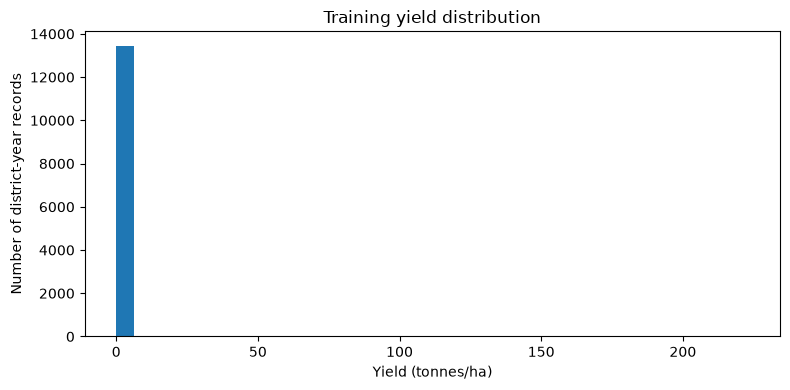

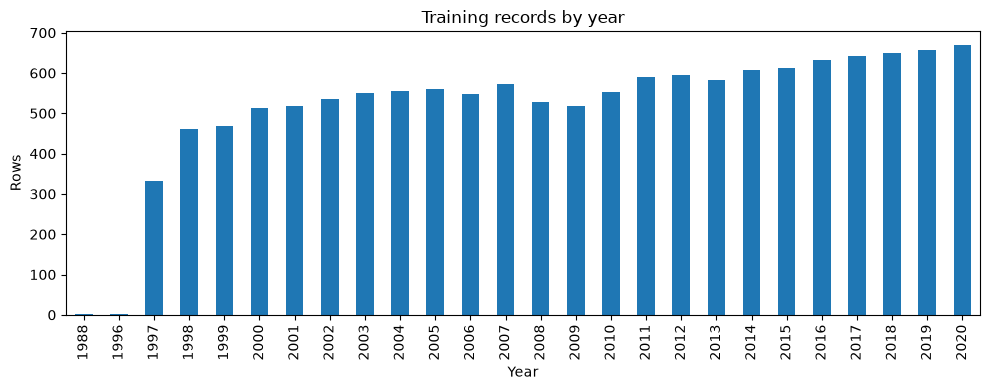

training_records
state          district                         
ANDHRA PRADESH GUNTUR                         24
WEST BENGAL    PURULIA                        24
               PURBA BARDHAMAN                24
               NADIA                          24
               MURSHIDABAD                    24
               MEDINIPUR WEST                 24
ANDHRA PRADESH ANANTAPUR                      24
               CHITTOOR                       24
WEST BENGAL    MALDAH                         24
ANDHRA PRADESH EAST GODAVARI                  24
MAHARASHTRA    AHMEDNAGAR                     24
               AMRAVATI                       24
               BEED                           24
UTTAR PRADESH  MAU                            24
               MEERUT                         24

,training_yield_t_ha
count,13457.000000
mean,2.108491
std,2.165889
min,0.000000
25%,1.350000
50%,2.030000
75%,2.700000
max,223.130000


In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(train["yield_t_ha"], bins=35)
ax.set_title("Training yield distribution")
ax.set_xlabel("Yield (tonnes/ha)")
ax.set_ylabel("Number of district-year records")
plt.tight_layout()
plt.show()

year_counts = train.groupby("year").size()
fig, ax = plt.subplots(figsize=(10, 4))
year_counts.plot(kind="bar", ax=ax)
ax.set_title("Training records by year")
ax.set_xlabel("Year")
ax.set_ylabel("Rows")
plt.tight_layout()
plt.show()

district_counts = train.groupby(["state", "district"]).size().sort_values(ascending=False)
display(district_counts.head(15).rename("training_records").to_frame())
display(train["yield_t_ha"].describe().to_frame("training_yield_t_ha"))

**Write in your report after viewing the training-only outputs:**
- Observation 1: describe the training target distribution (for example, skewness, range, or concentration), using the actual displayed values.
- Observation 2: describe variation in year coverage or district frequency, citing the displayed counts.
- Potential bias: locations with more historical observations may influence fitting more heavily; district boundaries and reporting practices may also change over time.

Do not write guessed numeric observations; copy values from your run.

## Task 3 — Fit preprocessing correctly

The source file lacks season, so categorical inputs are state and district; year is numeric. OneHotEncoder uses `handle_unknown='ignore'`. The year pipeline applies median imputation defensively and then standardization. All preprocessing is fitted only on training rows.

In [8]:
CATEGORICAL = ["state", "district"]
NUMERIC = ["year"]
FEATURES = CATEGORICAL + NUMERIC
TARGET = "yield_t_ha"

def make_preprocessor():
    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])
    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    return ColumnTransformer([
        ("categorical", categorical_pipe, CATEGORICAL),
        ("numeric", numeric_pipe, NUMERIC)
    ])

def make_pipeline(estimator):
    return Pipeline([
        ("preprocess", make_preprocessor()),
        ("model", estimator)
    ])

X_train, y_train = train[FEATURES], train[TARGET]
X_valid, y_valid = valid[FEATURES], valid[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

# Fit a preprocessing-only pipeline on training rows to inspect learned categories.
preprocessor = make_preprocessor()
preprocessor.fit(X_train, y_train)
ohe = preprocessor.named_transformers_["categorical"].named_steps["onehot"]
learned_categories = {col: list(vals) for col, vals in zip(CATEGORICAL, ohe.categories_)}
print("Learned category counts:", {k: len(v) for k, v in learned_categories.items()})

Learned category counts: {'state': 36, 'district': 734}


### Demonstrate validation-only categories do not enter encoder categories

This checks whether any category present in validation but absent in training is missing from the fitted training encoder's category list. Such categories are ignored by the fitted encoder rather than causing an error.

In [9]:
category_audit = []
for col, cats in zip(CATEGORICAL, ohe.categories_):
    train_cats = set(train[col].dropna().astype(str).unique())
    valid_cats = set(valid[col].dropna().astype(str).unique())
    valid_only = sorted(valid_cats - train_cats)
    learned = set(map(str, cats))
    category_audit.append({
        "column": col,
        "training_unique": len(train_cats),
        "validation_unique": len(valid_cats),
        "validation_only_count": len(valid_only),
        "validation_only_examples": ", ".join(valid_only[:10]),
        "validation_only_entered_encoder": bool(set(valid_only) & learned)
    })
category_audit = pd.DataFrame(category_audit)
display(category_audit)
category_audit.to_csv(OUT / "validation_category_audit.csv", index=False)

,column,training_unique,validation_unique,validation_only_count,validation_only_examples,validation_only_entered_encoder
0,state,36,32,0,,False
1,district,734,678,33,"33 PARAGANAS NORTH, 33 PARAGANAS SOUTH, 34 PAR...",False


## Task 4 and Task 5 — Baseline, tree, Ridge and Random Forest

### Predeclared model settings

- `median`: DummyRegressor with training median.
- `ridge_trend`: Ridge regression, alpha=1, solver=`lsqr`.
- `tree`: DecisionTreeRegressor, max_depth=6, min_samples_leaf=10, random_state=42.
- `forest`: RandomForestRegressor, 60 trees, max_depth=12, min_samples_leaf=5, random_state=42, n_jobs=2.

**Prediction before fitting:** Ridge can represent a smooth linear year trend after scaling and may extrapolate a linear trend more naturally than a tree. A tree/forest partitions the observed feature space and generally does not extrapolate a rising temporal trend beyond learned terminal regions. However, district/state categorical features and nonlinearity can change the empirical result. The validation metrics decide the selection; this prediction is a hypothesis, not a result.

In [10]:
MODEL_FACTORIES = {
    "median": lambda: DummyRegressor(strategy="median"),
    "ridge_trend": lambda: Ridge(alpha=1.0, solver="lsqr"),
    "tree": lambda: DecisionTreeRegressor(max_depth=6, min_samples_leaf=10, random_state=42),
    "forest": lambda: RandomForestRegressor(
        n_estimators=60, max_depth=12, min_samples_leaf=5,
        n_jobs=2, random_state=42
    )
}
MODEL_SETTINGS = {
    "median": "DummyRegressor(strategy='median')",
    "ridge_trend": "Ridge(alpha=1.0, solver='lsqr')",
    "tree": "DecisionTreeRegressor(max_depth=6, min_samples_leaf=10, random_state=42)",
    "forest": "RandomForestRegressor(n_estimators=60, max_depth=12, min_samples_leaf=5, n_jobs=2, random_state=42)"
}

def regression_metrics(y_true, y_pred):
    return {
        "MAE_t_ha": float(mean_absolute_error(y_true, y_pred)),
        "RMSE_t_ha": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2": float(r2_score(y_true, y_pred)) if len(y_true) > 1 else np.nan
    }

# Confirm median baseline by hand/pandas.
training_median = float(y_train.median())
median_model = make_pipeline(MODEL_FACTORIES["median"]())
median_model.fit(X_train, y_train)
median_pred = median_model.predict(X_valid)
print("Training median calculated with pandas:", training_median)
print("DummyRegressor constant prediction:", float(np.asarray(median_model.named_steps["model"].constant_).item()))
assert np.allclose(median_pred, training_median)
print("Confirmed: baseline predictions equal the training median.")
print("Median is suitable for MAE because the median minimizes the sum of absolute deviations.")

Training median calculated with pandas: 2.03
DummyRegressor constant prediction: 2.03
Confirmed: baseline predictions equal the training median.
Median is suitable for MAE because the median minimizes the sum of absolute deviations.


In [11]:
validation_rows = []
fitted_models = {}
validation_predictions = {}
for name, factory in MODEL_FACTORIES.items():
    pipe = make_pipeline(factory())
    t0 = time.perf_counter()
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_valid)
    elapsed = time.perf_counter() - t0
    scores = regression_metrics(y_valid, pred)
    validation_rows.append({
        "model": name,
        **scores,
        "fit_plus_validation_prediction_seconds": elapsed,
        "settings": MODEL_SETTINGS[name]
    })
    fitted_models[name] = pipe
    validation_predictions[name] = pred

validation_results = pd.DataFrame(validation_rows).sort_values(
    ["MAE_t_ha", "RMSE_t_ha"], kind="stable"
).reset_index(drop=True)
display(validation_results)
validation_results.to_csv(OUT / "validation_results.csv", index=False)

,model,MAE_t_ha,RMSE_t_ha,R2,fit_plus_validation_prediction_seconds,settings
0,ridge_trend,0.444447,0.779771,0.328854,0.148444,"Ridge(alpha=1.0, solver='lsqr')"
1,forest,0.501631,0.768083,0.348823,2.921410,"RandomForestRegressor(n_estimators=60, max_dep..."
2,tree,0.599680,0.854156,0.194699,0.134515,"DecisionTreeRegressor(max_depth=6, min_samples..."
3,median,0.850264,1.138439,-0.430550,0.100521,DummyRegressor(strategy='median')


### Optional training-versus-validation diagnostic

This diagnostic is not used as a new selection rule. Large gaps can indicate overfitting, but comparisons should account for the fact that training and validation are different time periods.

In [12]:
diagnostics = []
for name, pipe in fitted_models.items():
    tr_pred = pipe.predict(X_train)
    va_pred = pipe.predict(X_valid)
    diagnostics.append({
        "model": name,
        "train_MAE_t_ha": mean_absolute_error(y_train, tr_pred),
        "validation_MAE_t_ha": mean_absolute_error(y_valid, va_pred),
        "train_RMSE_t_ha": np.sqrt(mean_squared_error(y_train, tr_pred)),
        "validation_RMSE_t_ha": np.sqrt(mean_squared_error(y_valid, va_pred))
    })
diagnostics = pd.DataFrame(diagnostics)
display(diagnostics)
diagnostics.to_csv(OUT / "train_validation_diagnostics.csv", index=False)

,model,train_MAE_t_ha,validation_MAE_t_ha,train_RMSE_t_ha,validation_RMSE_t_ha
0,median,0.814502,0.850264,2.167231,1.138439
1,ridge_trend,0.349531,0.444447,1.933294,0.779771
2,tree,0.629743,0.599680,1.975460,0.854156
3,forest,0.482128,0.501631,1.876568,0.768083


## Task 6 — Commit model selection

Selection is made solely by validation MAE. Exact ties retain the earlier candidate in the declared order: median, Ridge, tree, forest. The chosen pipeline remains fitted on training rows only; there is no refit on train plus validation. Save the selection record before opening the test set.

In [13]:
candidate_order = ["median", "ridge_trend", "tree", "forest"]
selection_table = validation_results.set_index("model").reindex(candidate_order).reset_index()
selected_name = selection_table.sort_values("MAE_t_ha", kind="stable").iloc[0]["model"]
selection_record = {
    "selected_model": selected_name,
    "selection_rule": "minimum validation MAE; ties preserve declared candidate order",
    "candidate_order": candidate_order,
    "selected_settings": MODEL_SETTINGS[selected_name],
    "validation_years": validation_years,
    "test_years_reserved": test_years,
    "training_only_fit": True,
    "features": FEATURES,
    "target": TARGET,
    "raw_sha256": RAW_SHA256,
    "season_missing_adaptation": "Season omitted; instructor approval required"
}
with open(OUT / "selection.json", "w", encoding="utf-8") as f:
    json.dump(selection_record, f, indent=2)
joblib.dump(fitted_models[selected_name], OUT / "selected_pipeline_pretest.joblib")
print(json.dumps(selection_record, indent=2))
print("Instructor check-off should be obtained here before running the test section.")

{
  "selected_model": "ridge_trend",
  "selection_rule": "minimum validation MAE; ties preserve declared candidate order",
  "candidate_order": [
    "median",
    "ridge_trend",
    "tree",
    "forest"
  ],
  "selected_settings": "Ridge(alpha=1.0, solver='lsqr')",
  "validation_years": [
    2021,
    2022
  ],
  "test_years_reserved": [
    2023,
    2024
  ],
  "training_only_fit": true,
  "features": [
    "state",
    "district",
    "year"
  ],
  "target": "yield_t_ha",
  "raw_sha256": "74a017708b0c084600b334bec644e11c73817438a7e0786c86498eb632d5a2b9",
  "season_missing_adaptation": "Season omitted; instructor approval required"
}
Instructor check-off should be obtained here before running the test section.


## Task 7 — Open the test once

**Important:** This cell creates `TEST_LOCK` before scoring. If `TEST_LOCK` already exists, the cell refuses to score again. Do not delete the lock to try a different model. Use the existing saved results for reporting. If the cell fails partway through, inspect saved files and document the failure rather than changing the model after seeing test results.

In [14]:
TEST_LOCK = OUT / "TEST_LOCK"
if TEST_LOCK.exists():
    raise RuntimeError(
        f"{TEST_LOCK} already exists. The test has already been opened or started. "
        "Do not rerun test scoring or remove the lock for tuning."
    )

# Record the lock before any test target metrics are computed.
lock_record = {
    "created_utc": pd.Timestamp.utcnow().isoformat(),
    "raw_sha256": RAW_SHA256,
    "test_years": test_years,
    "selected_model": selected_name,
    "selection_sha256": hashlib.sha256((OUT / "selection.json").read_bytes()).hexdigest()
}
TEST_LOCK.write_text(json.dumps(lock_record, indent=2), encoding="utf-8")

selected_pipe = fitted_models[selected_name]  # trained on training rows only
selected_test_pred = selected_pipe.predict(X_test)
baseline_test_pred = fitted_models["median"].predict(X_test)

test_result_rows = []
for name, pred in [(selected_name, selected_test_pred), ("median_predeclared_baseline", baseline_test_pred)]:
    test_result_rows.append({"model": name, **regression_metrics(y_test, pred)})
test_results = pd.DataFrame(test_result_rows)
display(test_results)
test_results.to_csv(OUT / "test_results.csv", index=False)

test_predictions = test[["state", "district", "year", "yield_t_ha"]].copy()
test_predictions["selected_prediction_t_ha"] = selected_test_pred
test_predictions["residual_t_ha"] = test_predictions["yield_t_ha"] - test_predictions["selected_prediction_t_ha"]
test_predictions["absolute_error_t_ha"] = test_predictions["residual_t_ha"].abs()
test_predictions.to_csv(OUT / "test_predictions.csv", index=False)

,model,MAE_t_ha,RMSE_t_ha,R2
0,ridge_trend,0.388552,0.635615,0.523184
1,median_predeclared_baseline,0.833910,1.064220,-0.336676


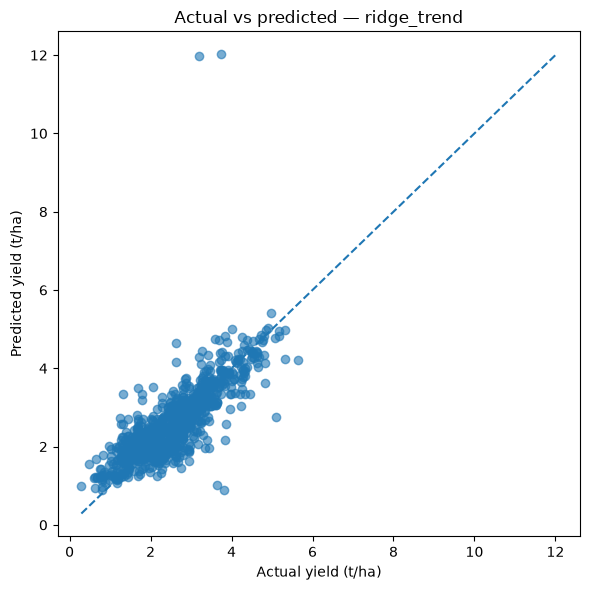

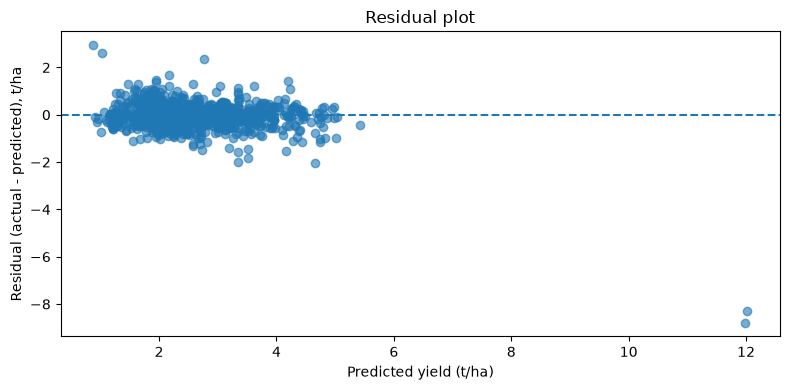

In [15]:
# Actual vs predicted plot
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, selected_test_pred, alpha=0.6)
lo = min(float(y_test.min()), float(np.min(selected_test_pred)))
hi = max(float(y_test.max()), float(np.max(selected_test_pred)))
ax.plot([lo, hi], [lo, hi], linestyle="--")
ax.set_xlabel("Actual yield (t/ha)")
ax.set_ylabel("Predicted yield (t/ha)")
ax.set_title(f"Actual vs predicted — {selected_name}")
plt.tight_layout()
plt.savefig(OUT / "actual_vs_predicted.png", dpi=160)
plt.show()

# Residual plot: residual = actual - predicted; positive means underprediction.
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(selected_test_pred, test_predictions["residual_t_ha"], alpha=0.6)
ax.axhline(0, linestyle="--")
ax.set_xlabel("Predicted yield (t/ha)")
ax.set_ylabel("Residual (actual - predicted), t/ha")
ax.set_title("Residual plot")
plt.tight_layout()
plt.savefig(OUT / "residuals.png", dpi=160)
plt.show()

### Largest nonzero errors and per-year robustness

Report up to five largest nonzero errors. If fewer than five nonzero errors exist, report all available nonzero errors and inspect additional correct/boundary cases without calling them failures. A positive residual means underprediction; a negative residual means overprediction.

In [16]:
nonzero_errors = test_predictions[test_predictions["absolute_error_t_ha"] > 0].sort_values(
    "absolute_error_t_ha", ascending=False
)
largest_errors = nonzero_errors.head(5)
display(largest_errors)
largest_errors.to_csv(OUT / "largest_five_nonzero_errors.csv", index=False)

if len(largest_errors) < 5:
    print(f"Only {len(largest_errors)} nonzero-error cases available. Do not label correct cases as failures.")
    display(test_predictions.sort_values("absolute_error_t_ha").head(5))

year_rows = []
for year, part in test_predictions.groupby("year"):
    year_rows.append({
        "year": int(year),
        "n": len(part),
        "MAE_t_ha": mean_absolute_error(part["yield_t_ha"], part["selected_prediction_t_ha"]),
        "RMSE_t_ha": np.sqrt(mean_squared_error(part["yield_t_ha"], part["selected_prediction_t_ha"])),
        "R2": r2_score(part["yield_t_ha"], part["selected_prediction_t_ha"]) if len(part) > 1 else np.nan
    })
year_robustness = pd.DataFrame(year_rows)
display(year_robustness)
year_robustness.to_csv(OUT / "year_robustness.csv", index=False)

,state,district,year,yield_t_ha,selected_prediction_t_ha,residual_t_ha,absolute_error_t_ha
8169,MAHARASHTRA,KOLHAPUR,2023,3.20,11.984499,-8.784499,8.784499
8168,MAHARASHTRA,KOLHAPUR,2024,3.73,12.020443,-8.290443,8.290443
4203,HARYANA,MAHENDRAGARH,2023,3.82,0.879523,2.940477,2.940477
11691,TAMIL NADU,CHENNAI,2023,3.65,1.025773,2.624227,2.624227
4657,HIMACHAL PRADESH,SOLAN,2023,5.11,2.762352,2.347648,2.347648


,year,n,MAE_t_ha,RMSE_t_ha,R2
0,2023,696,0.398681,0.621165,0.520862
1,2024,240,0.359178,0.675775,0.528689


## Task 8 — Reproduce, interpret, and acceptance checks

In [17]:
# Reload the saved pipeline and verify exact prediction reproducibility.
reload_pipe = joblib.load(OUT / "selected_pipeline_pretest.joblib")
reload_pred = reload_pipe.predict(X_test)
reproducible = bool(np.array_equal(selected_test_pred, reload_pred))
max_abs_difference = float(np.max(np.abs(selected_test_pred - reload_pred)))
print("Exact prediction equality:", reproducible)
print("Maximum absolute difference:", max_abs_difference)
assert reproducible, "Reloaded predictions are not exactly equal."

acceptance = {
    "raw_sha256": RAW_SHA256,
    "source_file_exists": DATA_PATH.exists(),
    "required_columns_present": set(required).issubset(raw.columns),
    "raw_rows": int(len(raw)),
    "canonical_rows": int(len(canonical)),
    "years_unique": int(canonical["year"].nunique()),
    "split_years_disjoint": (
        set(train["year"]).isdisjoint(valid["year"])
        and set(train["year"]).isdisjoint(test["year"])
        and set(valid["year"]).isdisjoint(test["year"])
    ),
    "target_finite_nonnegative": bool(np.isfinite(canonical[TARGET]).all() and (canonical[TARGET] >= 0).all()),
    "duplicate_keys_after_cleaning": int(canonical.duplicated(["state", "district", "year"]).sum()),
    "selected_model": selected_name,
    "test_lock_exists": TEST_LOCK.exists(),
    "reload_predictions_exact": reproducible,
    "season_column_missing": True,
    "instructor_approval_for_season_deviation": "PENDING"
}
with open(OUT / "acceptance.json", "w", encoding="utf-8") as f:
    json.dump(acceptance, f, indent=2)
print(json.dumps(acceptance, indent=2))

Exact prediction equality: True
Maximum absolute difference: 0.0
{
  "raw_sha256": "74a017708b0c084600b334bec644e11c73817438a7e0786c86498eb632d5a2b9",
  "source_file_exists": true,
  "required_columns_present": true,
  "raw_rows": 15735,
  "canonical_rows": 15717,
  "years_unique": 30,
  "split_years_disjoint": true,
  "target_finite_nonnegative": true,
  "duplicate_keys_after_cleaning": 0,
  "selected_model": "ridge_trend",
  "test_lock_exists": true,
  "reload_predictions_exact": true,
  "season_column_missing": true,
  "instructor_approval_for_season_deviation": "PENDING"
}


### Five plausible error causes (hypotheses, not established facts)

Use these as hypotheses to discuss, not as proven explanations for individual errors:

1. Missing irrigation, rainfall, soil, temperature, or water-availability variables may explain yield variation not represented by state, district, and year.
2. Changes in district boundaries or district naming may make historical observations less comparable.
3. Reporting revisions, rounding, or source-data anomalies may affect observed yield values.
4. Different rice varieties, planting practices, or input use may create within-district variation.
5. A small number of observations for some districts may make their learned categorical effects unstable.

The dataset does not include these explanatory fields, so this experiment cannot confirm which hypothesis explains a specific error.

## Rolling-origin robustness — three development origins

This diagnostic uses three one-year validation origins within development data only. At each origin, the model is freshly fitted on earlier years and evaluated on the next year. The final two test years are never used in these rolling-origin checks. These are descriptive stability checks, not confidence intervals. The selected model family is fixed by the validation-stage selection above.

In [18]:
development_years = sorted(set(train_years + validation_years))
if len(development_years) < 6:
    print("Not enough development years for three robust rolling origins.")
    rolling_results = pd.DataFrame()
else:
    # Choose the last three development years as one-year origins; training uses earlier years only.
    origins = development_years[-3:]
    rolling_rows = []
    for origin_year in origins:
        earlier_years = [yr for yr in development_years if yr < origin_year]
        origin_train = canonical[canonical["year"].isin(earlier_years)].copy()
        origin_valid = canonical[canonical["year"] == origin_year].copy()
        if origin_train.empty or origin_valid.empty:
            continue
        origin_pipe = make_pipeline(MODEL_FACTORIES[selected_name]())
        t0 = time.perf_counter()
        origin_pipe.fit(origin_train[FEATURES], origin_train[TARGET])
        pred = origin_pipe.predict(origin_valid[FEATURES])
        elapsed = time.perf_counter() - t0
        rolling_rows.append({
            "origin_year": int(origin_year),
            "training_max_year": int(max(earlier_years)),
            "training_rows": len(origin_train),
            "origin_rows": len(origin_valid),
            "MAE_t_ha": mean_absolute_error(origin_valid[TARGET], pred),
            "RMSE_t_ha": np.sqrt(mean_squared_error(origin_valid[TARGET], pred)),
            "R2": r2_score(origin_valid[TARGET], pred) if len(origin_valid) > 1 else np.nan,
            "fit_predict_seconds": elapsed
        })
    rolling_results = pd.DataFrame(rolling_rows)
    display(rolling_results)
    rolling_results.to_csv(OUT / "rolling_origins.csv", index=False)
    if not rolling_results.empty:
        print("Rolling-origin MAE mean:", rolling_results["MAE_t_ha"].mean())
        print("Rolling-origin MAE range:",
              rolling_results["MAE_t_ha"].min(), "to", rolling_results["MAE_t_ha"].max())

,origin_year,training_max_year,training_rows,origin_rows,MAE_t_ha,RMSE_t_ha,R2,fit_predict_seconds
0,2020,2019,12787,670,0.444780,0.939302,0.229268,0.155341
1,2021,2020,13457,648,0.374308,0.604801,0.511283,0.104018
2,2022,2021,14105,676,0.501264,0.903348,0.208119,0.094726


Rolling-origin MAE mean: 0.4401175001922841
Rolling-origin MAE range: 0.3743082050835556 to 0.501263998726203


## Evaluation interpretation prompts

Answer from your generated results, not from expectation:

1. Which model had the lowest validation MAE? What was its validation MAE in t/ha?
2. How did the selected model compare with the median baseline on the held-out test years?
3. Did the more complex forest provide a practically useful reduction in MAE/RMSE, or was the difference small?
4. Did one test year dominate pooled error? Include the sample count for each year.
5. Do residuals show systematic underprediction, overprediction, or a fan shape?
6. What limitations prevent interpreting the fitted associations as causal?
7. How does the missing season column change the scope of the conclusions?
8. What evidence supports source provenance and permission to reuse the CSV?

## Final artifact checklist

The `outputs_experiment08/` folder should contain:

- `provenance_record.json`
- `duplicate_key_conflicts.csv`
- `excluded_invalid_rows.csv`
- `rice_canonical_audit.csv`
- `split_manifest.csv`
- `validation_category_audit.csv`
- `validation_results.csv`
- `train_validation_diagnostics.csv`
- `selection.json`
- `selected_pipeline_pretest.joblib`
- `TEST_LOCK`
- `test_results.csv`
- `test_predictions.csv`
- `actual_vs_predicted.png`
- `residuals.png`
- `largest_five_nonzero_errors.csv`
- `year_robustness.csv`
- `acceptance.json`
- `rolling_origins.csv`

### Limitations to state in the report

- Season is absent; the manual's season-aware contract is not met.
- Source provenance and licence must be verified and recorded.
- Area/production/yield consistency and reporting definitions may vary by source/year.
- District boundary changes, repeated locations, missing environmental and agronomic features, and reporting anomalies may affect predictions.
- This design assesses temporal performance, not spatial generalization to unseen districts.
- Two test years support descriptive year-wise comparison, not a credible temporal confidence interval.
- Model settings are fixed; no tuning on the test set is permitted.
- Feature associations are not causal explanations.

## Suggested conclusion template

The experiment compared a training-median baseline, Ridge regression, a fixed-depth decision tree, and a Random Forest using chronological train/validation/test partitions. The selected model was **[fill from `selection.json`]**, chosen by validation MAE of **[value] t/ha**. On the untouched test years **[years]**, its MAE/RMSE/R² were **[values]**, compared with the median baseline **[values]**. Year-wise results showed **[summary with counts]**. Error inspection suggested possible roles for unobserved agronomic factors and data-quality variation, but these explanations remain hypotheses. The dataset lacks a season column and its source/licence record must be verified; therefore, findings apply only to the available state–district–year data and should not be described as season-specific pre-harvest forecasts.